# Introducción
## Objetivo
El proyecto consta de hacer un detector de objetos que incumplan estándares de vestimenta en un departamento de pintura para Ford Motor Company.  

El objetivo es impedir daños a la pintura de los vehículos en las líneas de ensamblaje, por lo que detectar e ilustrar la detección en video permite retroalimentar al personal con lo que debe de corregir.

## Unidad de análisis
Tras capturar imágenes de personal con diferentes niveles de cumplimiento se generó un .csv con datos de las coordenadas de los artículos que porta el personal que incumplen.  Derivado del mismo .csv se extrajeron muestras de los objetos y se almacenaron:  
* Imagenes originales:  Se encuentran almacenadas en _DataCapture/Raw_, tienen el rostro cubierto desde la adquisición por medio de código en OpenCV donde debe cumplirse la detección y sombreo de la cara para generar la captura
* Objetos con potencial de generar daño:  Se encuentran almacenados en la carpeta _DataCapture/NG_, dichas muestras serán de utilidad para entrenar un modelo con la capacidad de encontrarlos.
* Base de datos:  Es un csv localizado tambien en _DataCapture/anotaciones.csv_.  

En general el folder DataCapture está formulado para generar datos capturando sin rostro y con una libreta y pedazos de código capaces de permitir el rodeado de objetos por medio de una persona.  Dicho ésto el objetivo es tener datos etiquetados para un posterior *aprendizaje supervisado*.  

## Operaciones futuras
El uso de los scripts permitirá aumentar las muestras en un futuro para asegurar reentrenamiento

# Estructura de los datos
## Inventario y esquema
Al momento se lograron generar 41 imagenes con un total de 68 items identificados como potencial generador de daños a la pintura. 

| Datos        | Cantidad     | Formato
|--------------|--------------|----------|
| Imagenes Originales | 41 | .jpg  |
| Objetos Recortados  | 68 | .jpg  |
| Base de anotaciones | 1 | .csv |



In [1]:
## Conteo actualizado de imágenes y anotaciones
from pathlib import Path
import pandas as pd

#EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
EXTENSIONS = {".jpg"}
RAW_DIR = Path("../DataCapture/raw")
ObjectDir = Path("../DataCapture/NG")

for ext in EXTENSIONS:
    raw_files = list(RAW_DIR.glob(f"*{ext}"))
    print(f"Se encontraron {len(raw_files)} imágenes {ext}.")

for ext in EXTENSIONS:
    object_files = list(ObjectDir.glob(f"*{ext}"))
    print(f"Se encontraron {len(object_files)} objetos {ext}.")

df = pd.read_csv("../DataCapture/anotaciones.csv")
print(f"Se encontraron {len(df)} anotaciones en el archivo CSV.")


Se encontraron 45 imágenes .jpg.
Se encontraron 67 objetos .jpg.
Se encontraron 74 anotaciones en el archivo CSV.


## Calidad e integridad  
Al momento se hizo depuración manual de las imagenes ya que se encontraron un total de 20 imágenes desenfocadas con donde se estaban borrando objetos clave.

In [2]:
## Detectando imágenes sin anotaciones
# Obtener la lista de imágenes anotadas
df_dropna = df.dropna(subset=["x", "y"])
#df_dropna.groupby("imagen").size().reset_index(name="count")

print("Imágenes con anotaciones:")
df_dropna.groupby("imagen").size().reset_index(name="count")
#df_dropna.groupby("imagen").reset_index(name="count")

Imágenes con anotaciones:


,imagen,count
0,captura_20261003_153016_534962.jpg,1
1,captura_20261003_153021_540685.jpg,1
2,captura_20261003_153051_624221.jpg,1
3,captura_20261003_153056_648946.jpg,1
4,captura_20261003_153101_657504.jpg,1
5,captura_20261003_153838_135146.jpg,2
6,captura_20261003_153944_399966.jpg,2
7,captura_20261003_153949_427154.jpg,2
8,captura_20261003_153954_440259.jpg,2
9,captura_20261003_154213_767364.jpg,1


### Valores faltantes, duplicados y consistencia del CSV
Antes de analizar las coordenadas se revisa si el archivo de anotaciones tiene valores faltantes, si siguen algún patrón y si el CSV es consistente con las carpetas `raw` y `NG`.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

COORDS = ["x", "y", "w", "h"]

print("Dimensiones del CSV:", df.shape)
print("\nTipos de dato por columna:")
print(df.dtypes.to_string())

resumen_faltantes = pd.DataFrame({
    "faltantes": df.isnull().sum(),
    "porcentaje": (df.isnull().mean() * 100).round(1),
})
print("\nValores faltantes por columna:")
display(resumen_faltantes)

# Patrón de ausencia: ¿faltan coordenadas sueltas o filas completas?
faltantes_por_fila = df[COORDS].isnull().sum(axis=1)
print("Coordenadas faltantes por fila (0 = fila completa, 4 = fila vacía):")
print(faltantes_por_fila.value_counts().sort_index().to_string())

Dimensiones del CSV: (74, 7)

Tipos de dato por columna:
imagen             str
x              float64
y              float64
w              float64
h              float64
ImageWidth     float64
ImageHeight    float64

Valores faltantes por columna:


,faltantes,porcentaje
imagen,0,0.0
x,6,8.1
y,6,8.1
w,6,8.1
h,6,8.1
ImageWidth,6,8.1
ImageHeight,6,8.1


Coordenadas faltantes por fila (0 = fila completa, 4 = fila vacía):
0    68
4     6


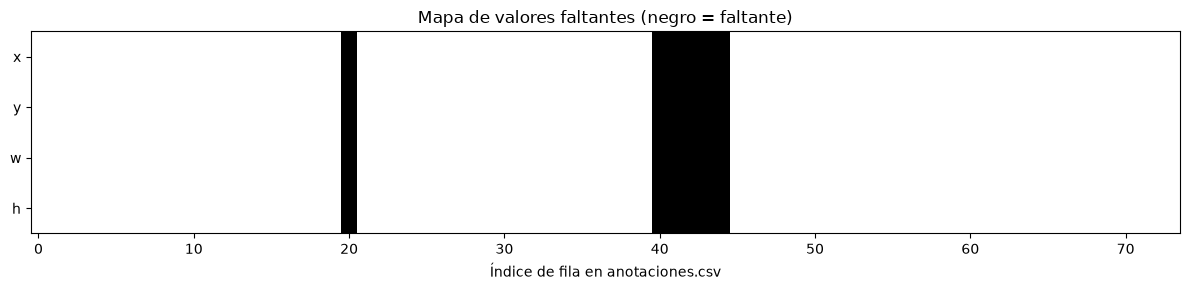

In [4]:
## Mapa de valores faltantes para identificar patrones de ausencia
fig, ax = plt.subplots(figsize=(12, 3))
ax.imshow(df[COORDS].isnull().values.T, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_yticks(range(len(COORDS)), COORDS)
ax.set_xlabel("Índice de fila en anotaciones.csv")
ax.set_title("Mapa de valores faltantes (negro = faltante)")
plt.tight_layout()
plt.show()

In [5]:
## Clasificación de las filas vacías y consistencia con las carpetas
filas_vacias = df[df[COORDS].isnull().all(axis=1)]
imagenes_con_objetos = set(df_dropna["imagen"])

vacias_redundantes = filas_vacias[filas_vacias["imagen"].isin(imagenes_con_objetos)]
vacias_sin_objetos = filas_vacias[~filas_vacias["imagen"].isin(imagenes_con_objetos)]
imagenes_sin_objetos = sorted(vacias_sin_objetos["imagen"].unique())

print(f"Filas con coordenadas (objetos anotados): {len(df_dropna)}")
print(f"Filas vacías de imágenes que SÍ tienen objetos (redundantes): {len(vacias_redundantes)}")
print(f"Filas vacías de imágenes SIN objetos: {len(vacias_sin_objetos)} "
      f"({len(imagenes_sin_objetos)} imágenes únicas)")
print(f"Filas duplicadas exactas: {df.duplicated().sum()}")

print("\nImágenes sin ningún objeto anotado (personal que cumple):")
for nombre in imagenes_sin_objetos:
    print("  -", nombre)

imagenes_raw = {p.name for p in raw_files}
imagenes_csv = set(df["imagen"])
print("\nImágenes en raw sin registro en el CSV:", sorted(imagenes_raw - imagenes_csv) or "ninguna")
print("Registros del CSV sin imagen en raw:", sorted(imagenes_csv - imagenes_raw) or "ninguno")
print(f"Recortes en NG: {len(object_files)} | objetos anotados en el CSV: {len(df_dropna)}")

Filas con coordenadas (objetos anotados): 68
Filas vacías de imágenes que SÍ tienen objetos (redundantes): 0
Filas vacías de imágenes SIN objetos: 6 (6 imágenes únicas)
Filas duplicadas exactas: 0

Imágenes sin ningún objeto anotado (personal que cumple):
  - captura_20261003_154645_222942.jpg
  - captura_20261003_161925_712237.jpg
  - captura_20261003_162026_088347.jpg
  - captura_20261003_162111_400265.jpg
  - captura_20261003_162116_408782.jpg
  - captura_20261003_162121_428795.jpg

Imágenes en raw sin registro en el CSV: ninguna
Registros del CSV sin imagen en raw: ['captura_20261019_105156_401150.jpg']
Recortes en NG: 67 | objetos anotados en el CSV: 68


**Interpretación.**
* Las columnas `x, y, w, h` tienen 46 valores faltantes (40.4 %) y **siempre faltan las cuatro a la vez**: no hay filas con coordenadas parciales.
* El mapa muestra que la ausencia **no es aleatoria**: se concentra en dos bloques.
  1. **10 filas de 5 imágenes sin objetos** (capturas de 16:19 a 16:21), es decir, personal que cumple. 5 de esas filas son duplicados exactos.
  2. **36 filas al final del archivo** que repiten, sin coordenadas, imágenes que sí tienen objetos. Es un bloque redundante, probablemente generado por la herramienta de anotación al registrar cada imagen revisada.
* El CSV es consistente con las carpetas: las 41 imágenes de `raw` tienen registro y los 68 objetos anotados coinciden con los 68 recortes de `NG`.

**Decisión:** no se imputan valores, porque una fila vacía no es un dato perdido: es una imagen sin objetos o un registro redundante. El tratamiento se aplica en la sección *Procesamiento*.

# Análisis univariante

Se describe cada variable por separado en tres niveles:
1. **Imágenes completas** (`raw`): distribución de color, resolución, tamaño de archivo, brillo, contraste y nitidez.
2. **Anotaciones** (`anotaciones.csv`): posición, tamaño y forma de las cajas de cada objeto.
3. **Recortes** (`NG`): tamaño y apariencia de los objetos recortados.

Primero se comparan los histogramas RGB de cada imagen contra el histograma promedio para encontrar imágenes atípicas.

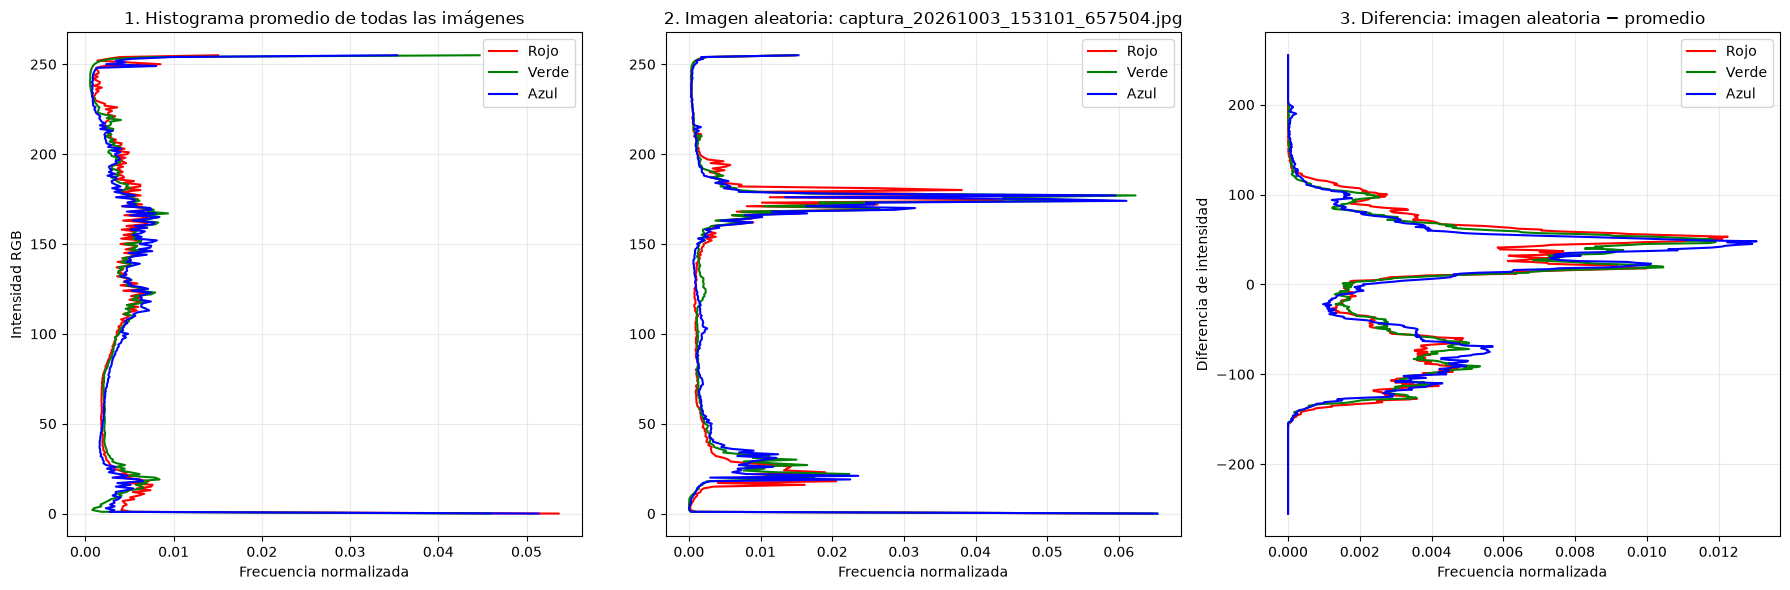

In [6]:
from PIL import Image
import numpy as np

import matplotlib.pyplot as plt

# Igualar dimensiones para poder calcular la imagen promedio píxel a píxel.
# Se usa la resolución de la primera imagen como referencia.
image_paths = sorted(RAW_DIR.glob("*.jpg"))
if not image_paths:
    raise FileNotFoundError(f"No se encontraron imágenes en {RAW_DIR}")

with Image.open(image_paths[0]) as first_image:
    target_size = first_image.size

images_rgb = []
for path in image_paths:
    with Image.open(path) as image:
        image = image.convert("RGB").resize(target_size)
        images_rgb.append(np.asarray(image, dtype=np.float32))

# Elige una imagen aleatoria reproducible y calcula el promedio píxel a píxel.
rng = np.random.default_rng(42)
sample_index = rng.integers(len(images_rgb))
sample_image = images_rgb[sample_index]
mean_image = np.mean(images_rgb, axis=0)
difference = sample_image - mean_image

channel_colors = ["red", "green", "blue"]
channel_names = ["Rojo", "Verde", "Azul"]

# Histogramas normalizados; se grafican horizontalmente (intensidad en el eje Y).
average_histograms = []
for channel in range(3):
    per_image = [
        np.histogram(image[:, :, channel], bins=256, range=(0, 256), density=True)[0]
        for image in images_rgb
    ]
    average_histograms.append(np.mean(per_image, axis=0))

sample_histograms = [
    np.histogram(sample_image[:, :, c], bins=256, range=(0, 256), density=True)[0]
    for c in range(3)
]

difference_bins = np.arange(-255.5, 256.5, 1)
difference_histograms = [
    np.histogram(difference[:, :, c], bins=difference_bins, density=True)[0]
    for c in range(3)
]
difference_centers = (difference_bins[:-1] + difference_bins[1:]) / 2

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=False)

for c, color in enumerate(channel_colors):
    axes[0].plot(average_histograms[c], np.arange(256), color=color, label=channel_names[c])
    axes[1].plot(sample_histograms[c], np.arange(256), color=color, label=channel_names[c])
    axes[2].plot(
        difference_histograms[c], difference_centers, color=color, label=channel_names[c]
    )

axes[0].set_title("1. Histograma promedio de todas las imágenes")
axes[0].set_ylabel("Intensidad RGB")
axes[1].set_title(f"2. Imagen aleatoria: {image_paths[sample_index].name}")
axes[2].set_title("3. Diferencia: imagen aleatoria − promedio")
axes[2].set_ylabel("Diferencia de intensidad")

for ax in axes:
    ax.set_xlabel("Frecuencia normalizada")
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()

Utilizando el principio de "normalidad" se buscaron imagenes fuera de lugar o muy diferentes al resto.

,imagen,Diferencia promedio Rojo,Diferencia promedio Verde,Diferencia promedio Azul,Distancia euclideana
0,captura_20261022_130934_236528.jpg,0.005927,0.005868,0.006306,0.778273
1,captura_20261003_153944_399966.jpg,0.005050,0.005040,0.005296,0.491690
2,captura_20261003_155238_738227.jpg,0.001937,0.002090,0.002358,0.260301
3,captura_20261003_153954_440259.jpg,0.002791,0.002789,0.003015,0.217750
4,captura_20261003_153056_648946.jpg,0.003459,0.003530,0.003750,0.205047
5,captura_20261003_153101_657504.jpg,0.003442,0.003455,0.003772,0.196082
6,captura_20261003_153016_534962.jpg,0.003250,0.003592,0.003542,0.184640
7,captura_20261003_153949_427154.jpg,0.002034,0.002073,0.002370,0.181601
8,captura_20261019_105201_426138.jpg,0.002077,0.001588,0.001668,0.180586
9,captura_20261003_154700_253089.jpg,0.002371,0.002303,0.002714,0.173056


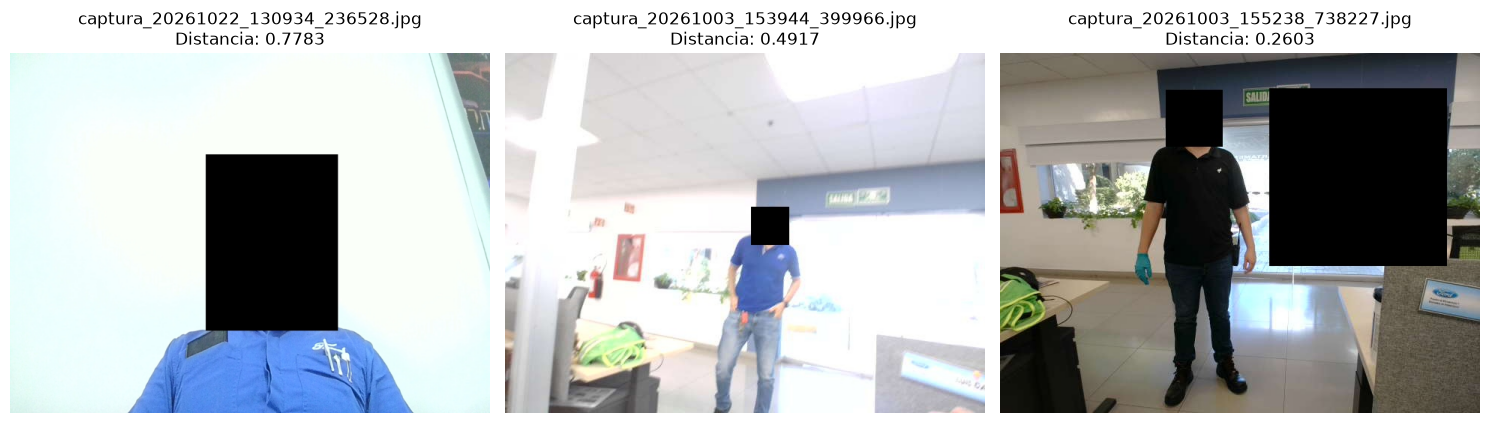

In [7]:
channel_names = ["Rojo", "Verde", "Azul"]
rows = []

for path, image_array in zip(image_paths, images_rgb):
    channel_differences = []

    for channel in range(3):
        image_histogram = np.histogram(
            image_array[:, :, channel],
            bins=256,
            range=(0, 256),
            density=True
        )[0]

        channel_differences.append(
            image_histogram - average_histograms[channel]
        )

    row = {"imagen": path.name}

    for channel, channel_name in enumerate(channel_names):
        row[f"Diferencia promedio {channel_name}"] = np.mean(
            np.abs(channel_differences[channel])
        )

    # Distancia euclideana sobre los 3 canales y todos los bins.
    row["Distancia euclideana"] = np.sqrt(
        sum(np.sum(diff ** 2) for diff in channel_differences)
    )
    rows.append(row)

df_diferencias_histograma = pd.DataFrame(rows).sort_values(
    "Distancia euclideana", ascending=False
).reset_index(drop=True)

display(df_diferencias_histograma)

# Mostrar las tres imágenes con mayor distancia al histograma promedio.
top3 = df_diferencias_histograma.head(3)
fig, axes = plt.subplots(1, len(top3), figsize=(15, 5))

for ax, (_, row) in zip(axes, top3.iterrows()):
    index = next(i for i, path in enumerate(image_paths) if path.name == row["imagen"])
    ax.imshow(images_rgb[index].astype(np.uint8))
    ax.set_title(f'{row["imagen"]}\nDistancia: {row["Distancia euclideana"]:.4f}')
    ax.axis("off")

plt.tight_layout()
plt.show()

Se observa que las 3 imagenes son significativamente diferentes:
1. Altamente iluminada por ajuste de sensibilidad del lente
2. Posee un cuadrado negro generado por el haarcasdade
3. Similar al anterior, posee un cuadrado negro que mueve al histograma

<Axes: title={'center': 'Histograma de distancias euclideanas al histograma promedio'}, ylabel='Frequency'>

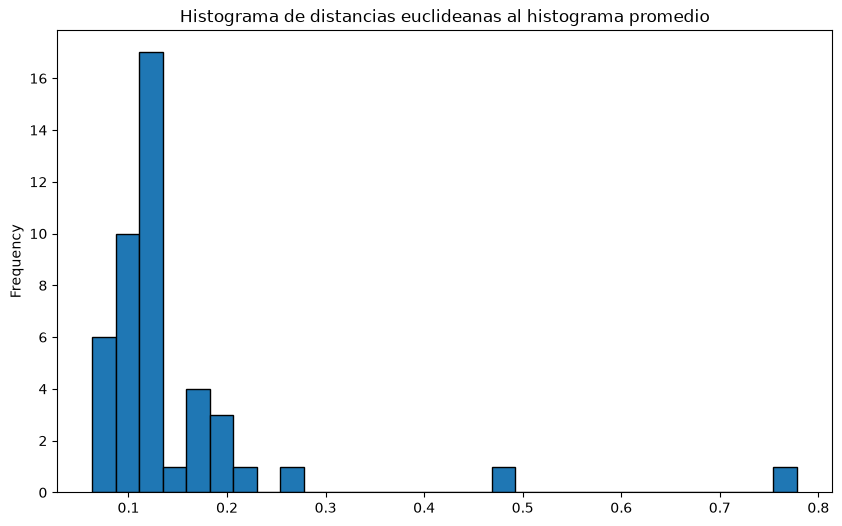

In [8]:
plt.title("Histograma de distancias euclideanas al histograma promedio")
df_diferencias_histograma["Distancia euclideana"].plot(kind="hist", bins=30, edgecolor="black", figsize=(10, 6))

Se determina que tales imágenes son anomalías, siendo solo la primera susceptible a eliminación por su diferencia significativa en la captura de iluminación.

## Propiedades de las imágenes completas
Para cada imagen se calculan: resolución, modo de color, tamaño del archivo, **brillo** (media de la escala de grises), **contraste** (desviación estándar) y **nitidez** (varianza del Laplaciano; valores bajos indican imágenes borrosas).

In [9]:
import cv2

registros = []
for path in image_paths:
    with Image.open(path) as im:
        ancho, alto = im.size
        modo = im.mode
        gris = np.asarray(im.convert("L"), dtype=np.float32)
    registros.append({
        "imagen": path.name,
        "ancho": ancho,
        "alto": alto,
        "proporcion": round(ancho / alto, 3),
        "modo": modo,
        "tamano_kb": path.stat().st_size / 1024,
        "brillo": gris.mean(),
        "contraste": gris.std(),
        "nitidez": cv2.Laplacian(gris, cv2.CV_32F).var(),
    })

df_img = pd.DataFrame(registros)
print("Resoluciones y modos de color encontrados:")
display(df_img.groupby(["ancho", "alto", "modo"]).size().reset_index(name="imagenes"))
print("Estadísticas resumidas de las imágenes:")
display(df_img[["tamano_kb", "brillo", "contraste", "nitidez"]].describe().round(2))

Resoluciones y modos de color encontrados:


,ancho,alto,modo,imagenes
0,640,480,RGB,41
1,1920,1080,RGB,4


Estadísticas resumidas de las imágenes:


,tamano_kb,brillo,contraste,nitidez
count,45.00,45.00,45.00,45.00
mean,65.34,123.27,68.12,394.06
std,41.60,22.84,7.21,171.15
min,31.09,78.69,44.28,54.71
25%,51.22,113.76,63.34,276.32
50%,56.63,122.02,70.20,401.66
75%,59.26,129.74,71.82,515.03
max,234.62,219.81,89.02,786.36


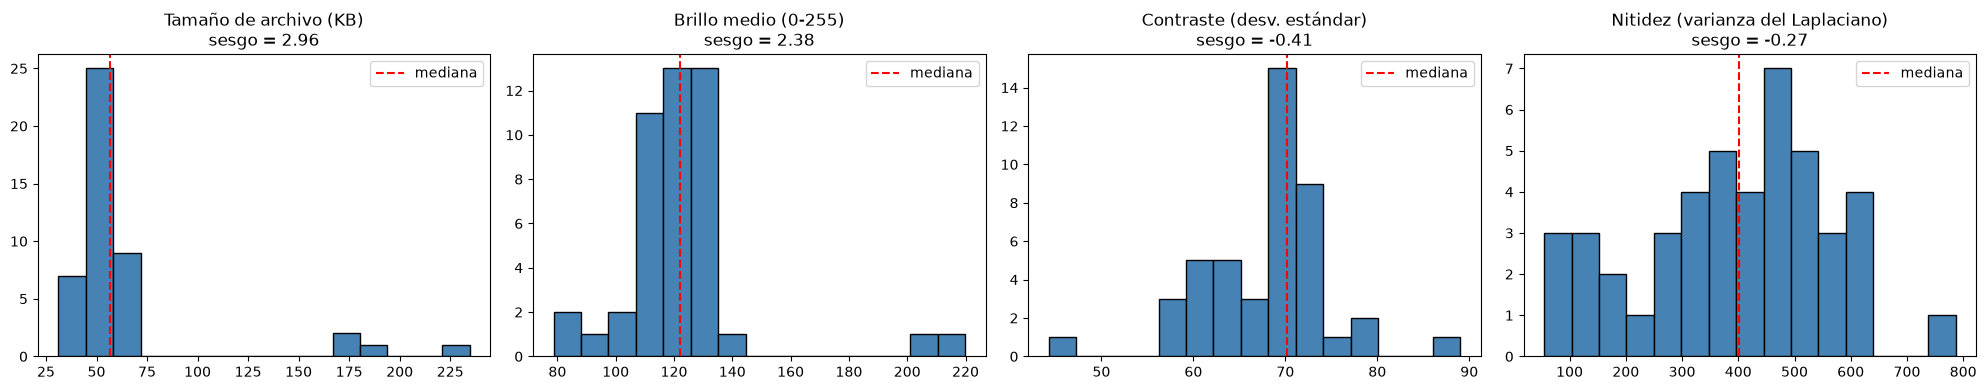

In [10]:
variables_img = {
    "tamano_kb": "Tamaño de archivo (KB)",
    "brillo": "Brillo medio (0-255)",
    "contraste": "Contraste (desv. estándar)",
    "nitidez": "Nitidez (varianza del Laplaciano)",
}
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (col, titulo) in zip(axes, variables_img.items()):
    ax.hist(df_img[col], bins=15, color="steelblue", edgecolor="black")
    ax.axvline(df_img[col].median(), color="red", linestyle="--", label="mediana")
    ax.set_title(f"{titulo}\nsesgo = {df_img[col].skew():.2f}")
    ax.legend()
plt.tight_layout()
plt.show()

**Interpretación.**
* Las 41 imágenes tienen **la misma resolución (640×480) y el mismo modo de color (RGB)**, así que no hace falta redimensionarlas para que sean comparables.
* **Brillo:** la mayoría está entre 110 y 135, pero una imagen llega a 220. Es la imagen sobreexpuesta que detectaron los histogramas, y ese único valor explica el sesgo positivo de 2.46.
* **Nitidez:** va de 98 a 786. Las imágenes con valores bajos están movidas o desenfocadas, porque las personas caminan frente a la cámara, y eso dificulta ver objetos pequeños.
* El tamaño de archivo y el contraste tienen un sesgo negativo moderado: unas pocas imágenes tienen menos detalle que el resto. No se transforman porque son variables descriptivas que no entran al modelo.

## Objetos por imagen y cardinalidad

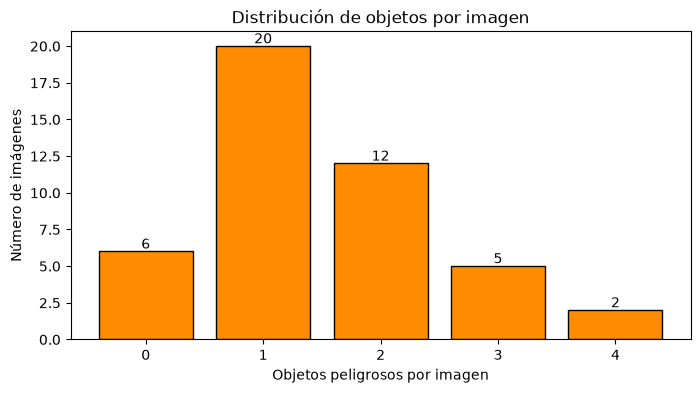

count    45.00
mean      1.49
std       1.01
min       0.00
25%       1.00
50%       1.00
75%       2.00
max       4.00


In [11]:
conteo = df_dropna.groupby("imagen").size()
df_img["n_objetos"] = df_img["imagen"].map(conteo).fillna(0).astype(int)

dist = df_img["n_objetos"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(dist.index, dist.values, color="darkorange", edgecolor="black")
for xi, yi in zip(dist.index, dist.values):
    ax.text(xi, yi + 0.2, str(yi), ha="center")
ax.set_xlabel("Objetos peligrosos por imagen")
ax.set_ylabel("Número de imágenes")
ax.set_title("Distribución de objetos por imagen")
plt.show()
print(df_img["n_objetos"].describe().round(2).to_string())

In [12]:
## Cardinalidad de las variables categóricas
cardinalidad = pd.DataFrame({
    "variable": ["imagen (CSV)", "modo de color", "resolución", "clase de objeto"],
    "valores_unicos": [df["imagen"].nunique(), df_img["modo"].nunique(),
                       df_img[["ancho", "alto"]].drop_duplicates().shape[0], 1],
    "registros": [len(df), len(df_img), len(df_img), len(df_dropna)],
})
display(cardinalidad)

,variable,valores_unicos,registros
0,imagen (CSV),46,74
1,modo de color,1,45
2,resolución,2,45
3,clase de objeto,1,68


**Interpretación de la cardinalidad.**
* `imagen` tiene **alta cardinalidad** (41 valores únicos en 114 registros), pero es un **identificador** que une el CSV con los archivos. No es una característica del modelo, así que no se codifica.
* El modo de color y la resolución tienen un solo valor: son constantes y no aportan información.
* Solo existe **una clase de objeto**: todo lo anotado es "objeto que puede dañar la pintura", sin distinguir entre pluma, gafete, broche o llaves. Se recomienda agregar una columna `tipo` en las próximas anotaciones para saber qué objetos son los más frecuentes y dar una retroalimentación más específica al personal.
* La mayoría de las imágenes tiene 1 o 2 objetos (mediana = 1, máximo = 5).

## Cajas delimitadoras de los objetos
A partir de `x, y, w, h` se derivan: área, proporción ancho/alto, centro de la caja (`xc`, `yc`) y porcentaje de la imagen que ocupa cada objeto. También se verifica que ninguna caja salga de los límites de la imagen.

In [13]:
ANCHO_IMG, ALTO_IMG = int(df_img["ancho"].mode()[0]), int(df_img["alto"].mode()[0])

df_obj = df_dropna.copy()
df_obj[COORDS] = df_obj[COORDS].astype(int)
df_obj["area"] = df_obj["w"] * df_obj["h"]
df_obj["proporcion"] = df_obj["w"] / df_obj["h"]
df_obj["xc"] = df_obj["x"] + df_obj["w"] / 2
df_obj["yc"] = df_obj["y"] + df_obj["h"] / 2
df_obj["area_rel_pct"] = df_obj["area"] / (ANCHO_IMG * ALTO_IMG) * 100

fuera = df_obj[(df_obj["x"] < 0) | (df_obj["y"] < 0) |
               (df_obj["x"] + df_obj["w"] > ANCHO_IMG) | (df_obj["y"] + df_obj["h"] > ALTO_IMG)]
print(f"Cajas fuera de los límites de la imagen: {len(fuera)}")
print(f"Cajas con ancho o alto <= 0: {((df_obj['w'] <= 0) | (df_obj['h'] <= 0)).sum()}")

variables_caja = ["x", "y", "w", "h", "area", "proporcion", "area_rel_pct"]
resumen = df_obj[variables_caja].describe().T
resumen["sesgo"] = df_obj[variables_caja].skew()
resumen["curtosis"] = df_obj[variables_caja].kurt()
print("Estadísticas resumidas de las cajas:")
display(resumen.round(2))

Cajas fuera de los límites de la imagen: 5
Cajas con ancho o alto <= 0: 0
Estadísticas resumidas de las cajas:


,count,mean,std,min,25%,50%,75%,max,sesgo,curtosis
x,68.0,336.53,196.08,43.00,253.25,295.00,346.75,1248.00,2.83,9.46
y,68.0,262.01,152.71,86.00,171.25,224.00,287.25,855.00,2.33,6.13
w,68.0,31.22,26.73,11.00,20.00,24.50,32.00,185.00,4.06,18.87
h,68.0,41.71,33.61,7.00,18.75,30.50,59.50,162.00,1.82,3.58
area,68.0,1872.75,3691.28,140.00,394.75,698.50,1521.00,21645.00,3.87,15.81
proporcion,68.0,0.96,0.57,0.26,0.54,0.83,1.24,3.17,1.56,3.47
area_rel_pct,68.0,0.61,1.20,0.05,0.13,0.23,0.50,7.05,3.87,15.81


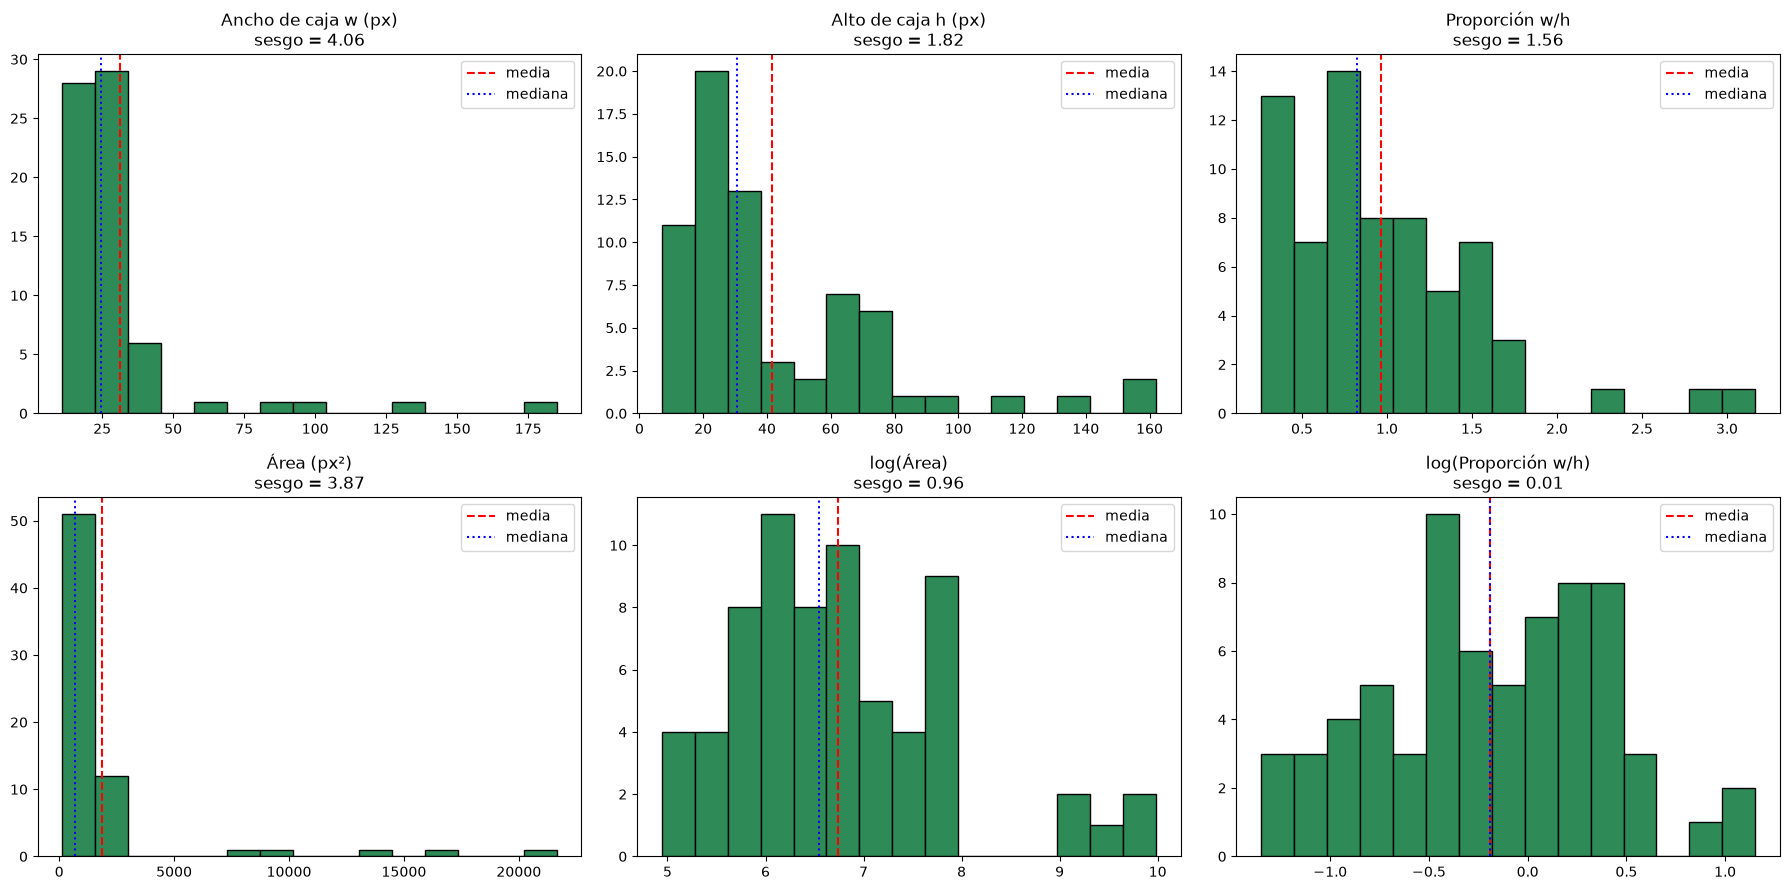

In [14]:
## Distribuciones y efecto de una transformación logarítmica
pares = [
    (df_obj["w"], "Ancho de caja w (px)"),
    (df_obj["h"], "Alto de caja h (px)"),
    (df_obj["proporcion"], "Proporción w/h"),
    (df_obj["area"], "Área (px²)"),
    (np.log(df_obj["area"]), "log(Área)"),
    (np.log(df_obj["proporcion"]), "log(Proporción w/h)"),
]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, (serie, titulo) in zip(axes.ravel(), pares):
    ax.hist(serie, bins=15, color="seagreen", edgecolor="black")
    ax.axvline(serie.mean(), color="red", linestyle="--", label="media")
    ax.axvline(serie.median(), color="blue", linestyle=":", label="mediana")
    ax.set_title(f"{titulo}\nsesgo = {serie.skew():.2f}")
    ax.legend()
plt.tight_layout()
plt.show()

**Interpretación.**
* Los objetos son **muy pequeños**: el ancho mediano es de 22 px y el alto mediano de 25 px. En promedio, cada caja ocupa solo el **0.26 %** de la imagen.
* `w` y `proporcion` tienen distribuciones casi simétricas (sesgo de 0.48 y 0.63).
* `h` y sobre todo **`area` están muy sesgadas a la derecha** (sesgo de 2.12 y 3.43; curtosis del área de 17). Casi todos son objetos pequeños, como broches y botones, y unos pocos son alargados, como lanyards o gafetes colgando.
* **Transformación no lineal:** con el logaritmo, el sesgo del área baja de 3.43 a 0.33 y la distribución queda aproximadamente simétrica. Por eso se usa `log(área)` en los análisis que asumen simetría.
* La proporción mediana es de 0.82, así que predominan las cajas un poco más altas que anchas.

### Valores atípicos en las cajas
Se usa el criterio del rango intercuartílico (IQR): un valor es atípico si está por debajo de Q1 − 1.5·IQR o por encima de Q3 + 1.5·IQR.

,atipicos_IQR
w,5
h,3
area,5
proporcion,3
log_area,3
log_proporcion,0


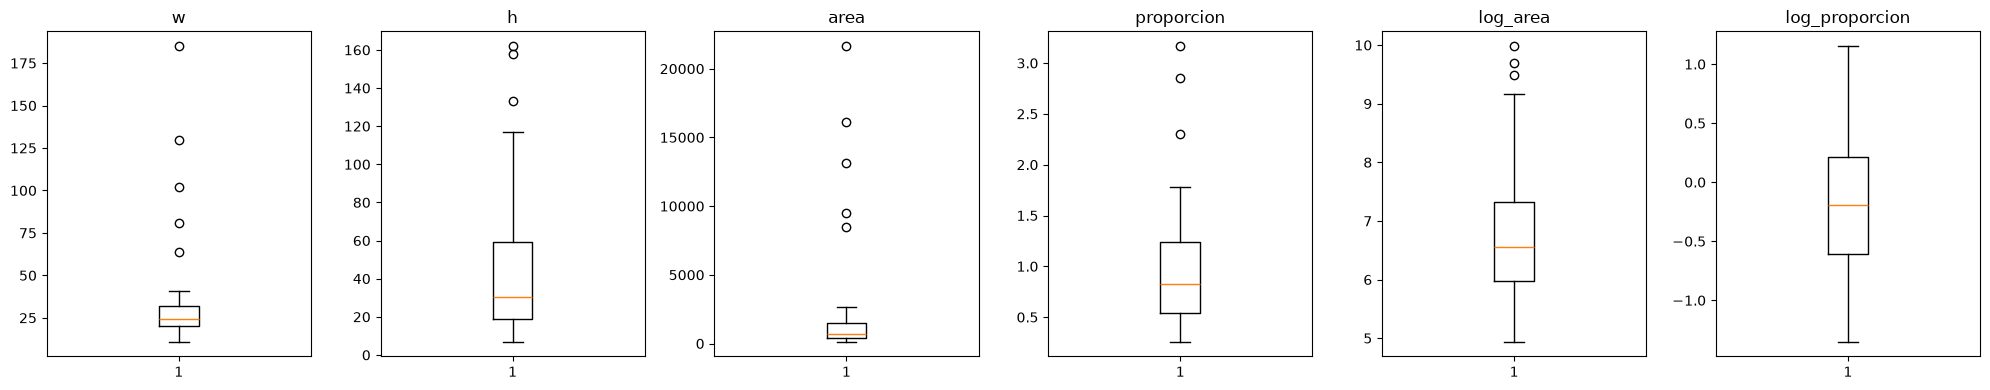

In [15]:
def atipicos_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)


df_obj["log_area"] = np.log(df_obj["area"])
df_obj["log_proporcion"] = np.log(df_obj["proporcion"])

cols_atip = ["w", "h", "area", "proporcion", "log_area", "log_proporcion"]
display(pd.DataFrame({"atipicos_IQR": [atipicos_iqr(df_obj[c]).sum() for c in cols_atip]}, index=cols_atip))

fig, axes = plt.subplots(1, len(cols_atip), figsize=(20, 4))
for ax, c in zip(axes, cols_atip):
    ax.boxplot(df_obj[c])
    ax.set_title(c)
plt.tight_layout()
plt.show()

Cajas atípicas por área o por proporción: 5


,imagen,x,y,w,h,area,proporcion
65,captura_20261003_221717_781755.jpg,43,86,64,133,8512,0.481203
68,captura_20261010_174008_715163.jpg,1046,771,102,158,16116,0.645570
71,captura_20261019_105201_426138.jpg,948,638,81,162,13122,0.500000
72,captura_20261022_130934_236528.jpg,1248,855,130,73,9490,1.780822
73,captura_20261022_130934_236528.jpg,694,807,185,117,21645,1.581197


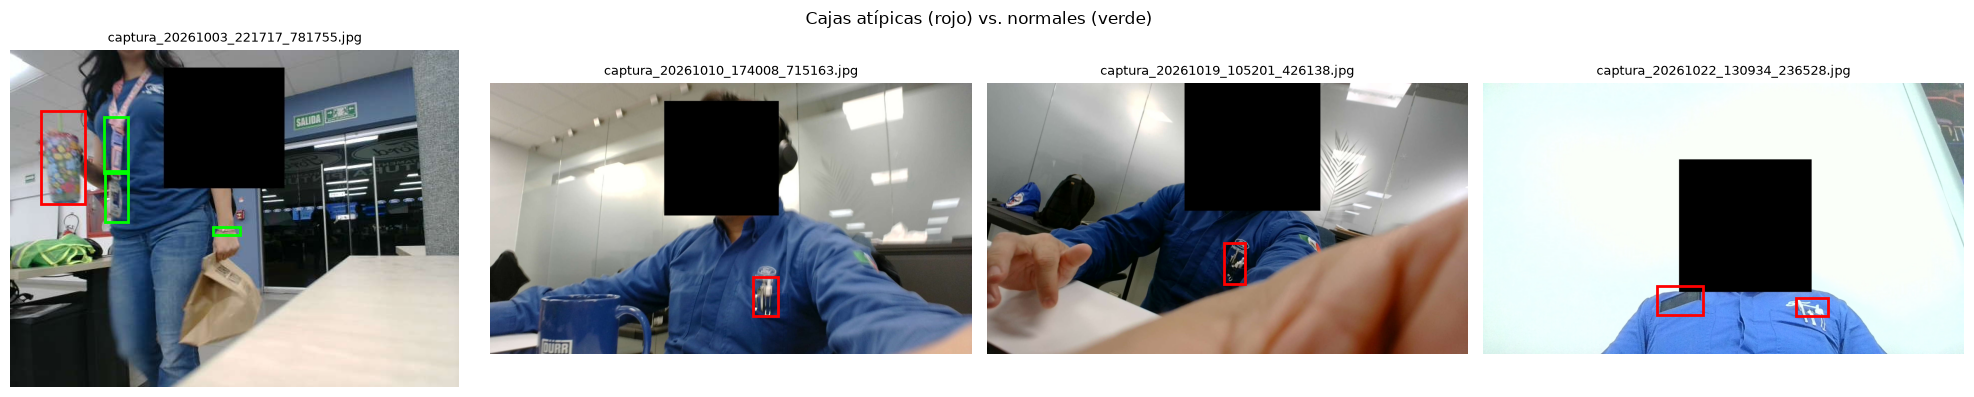

In [16]:
## Inspección visual de las cajas atípicas
atipicos = df_obj[atipicos_iqr(df_obj["area"]) | atipicos_iqr(df_obj["log_proporcion"])]
print(f"Cajas atípicas por área o por proporción: {len(atipicos)}")
display(atipicos[["imagen", "x", "y", "w", "h", "area", "proporcion"]])

imgs_atip = atipicos["imagen"].unique()[:4]
if len(imgs_atip) > 0:
    fig, axes = plt.subplots(1, len(imgs_atip), figsize=(5 * len(imgs_atip), 4))
    axes = np.atleast_1d(axes)
    for ax, nombre in zip(axes, imgs_atip):
        ax.imshow(Image.open(RAW_DIR / nombre).convert("RGB"))
        for idx, r in df_obj[df_obj["imagen"] == nombre].iterrows():
            color = "red" if idx in atipicos.index else "lime"
            ax.add_patch(plt.Rectangle((r["x"], r["y"]), r["w"], r["h"], fill=False, lw=2, edgecolor=color))
        ax.set_title(nombre, fontsize=9)
        ax.axis("off")
    plt.suptitle("Cajas atípicas (rojo) vs. normales (verde)")
    plt.tight_layout()
    plt.show()

**Interpretación.**
* Con el criterio IQR hay 3 cajas atípicas por área. Tras la transformación logarítmica queda solo 1, y la proporción en escala logarítmica ya no tiene atípicos.
* La revisión visual confirma que **son objetos reales y no errores de anotación**:
  * `153016_534962`: un objeto colgando de la bolsa de la camisa, fotografiado muy cerca de la cámara. En esta imagen, además, una mano tapa media escena.
  * `192522_301601`: un gafete colgando de un lanyard.
  * `221717_781755`: un lanyard largo de 39×138 px, el objeto más grande del conjunto.
* Como son ejemplos válidos y escasos, **se conservan** (ver *Procesamiento*).

## Recortes de objetos (carpeta NG)

Tamaño de los recortes (px):


,ancho,alto
count,67.0,67.0
mean,31.2,42.0
std,26.9,33.8
min,11.0,7.0
25%,20.0,18.5
50%,24.0,31.0
75%,32.0,60.0
max,185.0,162.0


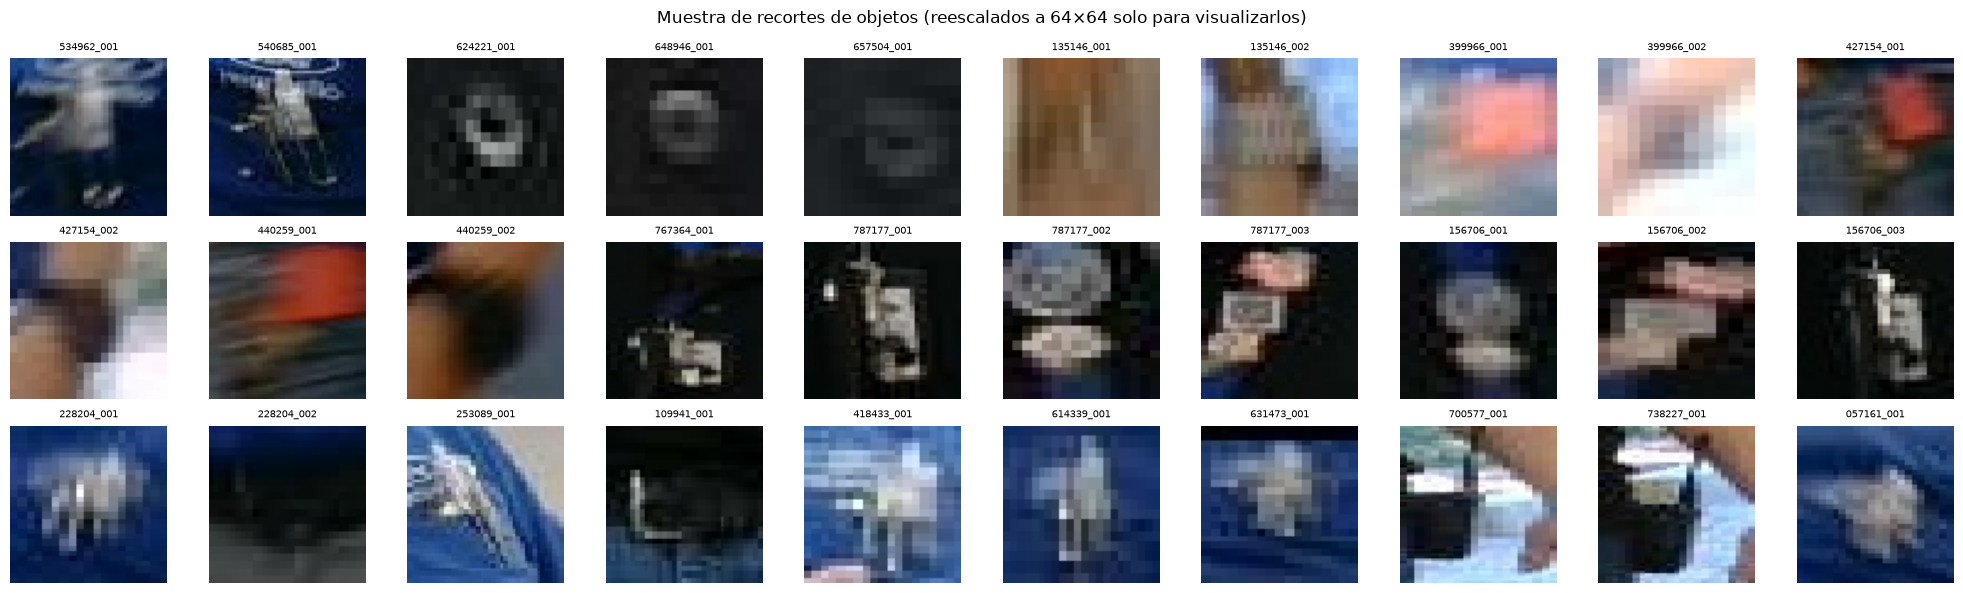

In [17]:
recortes = []
for p in sorted(object_files):
    with Image.open(p) as im:
        recortes.append({"archivo": p.name, "ancho": im.size[0], "alto": im.size[1]})
df_rec = pd.DataFrame(recortes)
print("Tamaño de los recortes (px):")
display(df_rec[["ancho", "alto"]].describe().round(1))

muestra = sorted(object_files)[:30]
fig, axes = plt.subplots(3, 10, figsize=(20, 6))
for ax, p in zip(axes.ravel(), muestra):
    ax.imshow(Image.open(p).convert("RGB").resize((64, 64), Image.Resampling.NEAREST))
    ax.set_title(p.stem[-10:], fontsize=7)
    ax.axis("off")
plt.suptitle("Muestra de recortes de objetos (reescalados a 64×64 solo para visualizarlos)")
plt.tight_layout()
plt.show()

**Interpretación.**
* El tamaño de los recortes coincide exactamente con las cajas del CSV (mediana de 22×25 px), lo que confirma que se generaron a partir de las anotaciones.
* Los objetos son variados: broches y pines metálicos, gafetes, clips, llaves y objetos de color rojo o naranja.
* Varios recortes están **borrosos por movimiento** (por ejemplo `440259_001` y `440259_002`), y en otros el objeto casi no se distingue por la oscuridad (`787177_002`, `156706_003`). Conviene revisar esas anotaciones y, en futuras capturas, mejorar la iluminación o pedir al personal que se detenga un momento frente a la cámara.

## Desequilibrio de clases (variable objetivo)
La variable objetivo es la **presencia de objetos que pueden dañar la pintura**. Se mide en dos niveles:
* **Por imagen:** ¿el trabajador cumple (sin objetos) o no cumple (con al menos un objeto)?
* **Por píxel:** ¿qué fracción de la imagen ocupan los objetos? Este es el desequilibrio que enfrenta un detector de objetos.

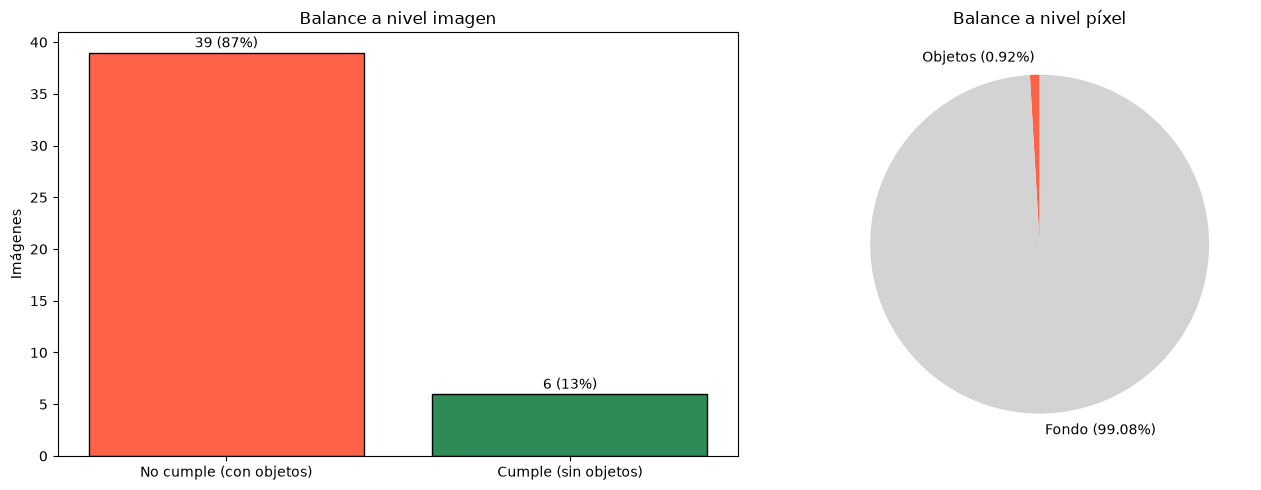

cumple
No cumple (con objetos)    39
Cumple (sin objetos)        6
Proporción de píxeles objeto : fondo = 1 : 108


In [18]:
df_img["cumple"] = np.where(df_img["n_objetos"] == 0, "Cumple (sin objetos)", "No cumple (con objetos)")
balance_img = df_img["cumple"].value_counts()

area_objetos = df_obj["area"].sum()
area_total = len(df_img) * ANCHO_IMG * ALTO_IMG
pct_obj = area_objetos / area_total * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colores = ["tomato" if "No" in etiqueta else "seagreen" for etiqueta in balance_img.index]
axes[0].bar(balance_img.index, balance_img.values, color=colores, edgecolor="black")
for i, v in enumerate(balance_img.values):
    axes[0].text(i, v + 0.5, f"{v} ({v / balance_img.sum():.0%})", ha="center")
axes[0].set_title("Balance a nivel imagen")
axes[0].set_ylabel("Imágenes")
axes[1].pie([area_objetos, area_total - area_objetos],
            labels=[f"Objetos ({pct_obj:.2f}%)", f"Fondo ({100 - pct_obj:.2f}%)"],
            colors=["tomato", "lightgray"], startangle=90)
axes[1].set_title("Balance a nivel píxel")
plt.tight_layout()
plt.show()

print(balance_img.to_string())
print(f"Proporción de píxeles objeto : fondo = 1 : {(area_total - area_objetos) / area_objetos:.0f}")

**Interpretación: hay un fuerte desequilibrio de clases.**
* **A nivel imagen:** 36 imágenes (88 %) son de personal que *no cumple* y solo 5 (12 %) de personal que *cumple*. Además, esas 5 imágenes se tomaron en una misma ráfaga de 2 minutos, así que tienen poca variedad.
* **A nivel píxel:** los objetos ocupan apenas el 0.43 % del área total; por cada píxel de objeto hay unos 232 de fondo. Es el desequilibrio típico de la detección de objetos pequeños.
* **Implicaciones:** a un clasificador *cumple / no cumple* le faltarían ejemplos negativos, y un detector tendrá que aprender a ignorar mucho fondo. Se propone:
  1. Capturar más personal con el uniforme correcto.
  2. Usar aumento de datos (*data augmentation*) sobre los objetos.
  3. Usar funciones de pérdida que compensen el desequilibrio, como la *focal loss* que ya incluyen los detectores tipo YOLO.

# Análisis bi/multivariante
Se estudian las relaciones entre variables:
1. Verificación visual de las anotaciones sobre las imágenes.
2. Tamaño vs. forma de las cajas y correlaciones entre sus variables.
3. Posición de los objetos dentro de la imagen.
4. Relación entre la calidad de la imagen y la categoría (cumple / no cumple).
5. Tendencias temporales entre sesiones de captura.

## Verificación visual de las anotaciones

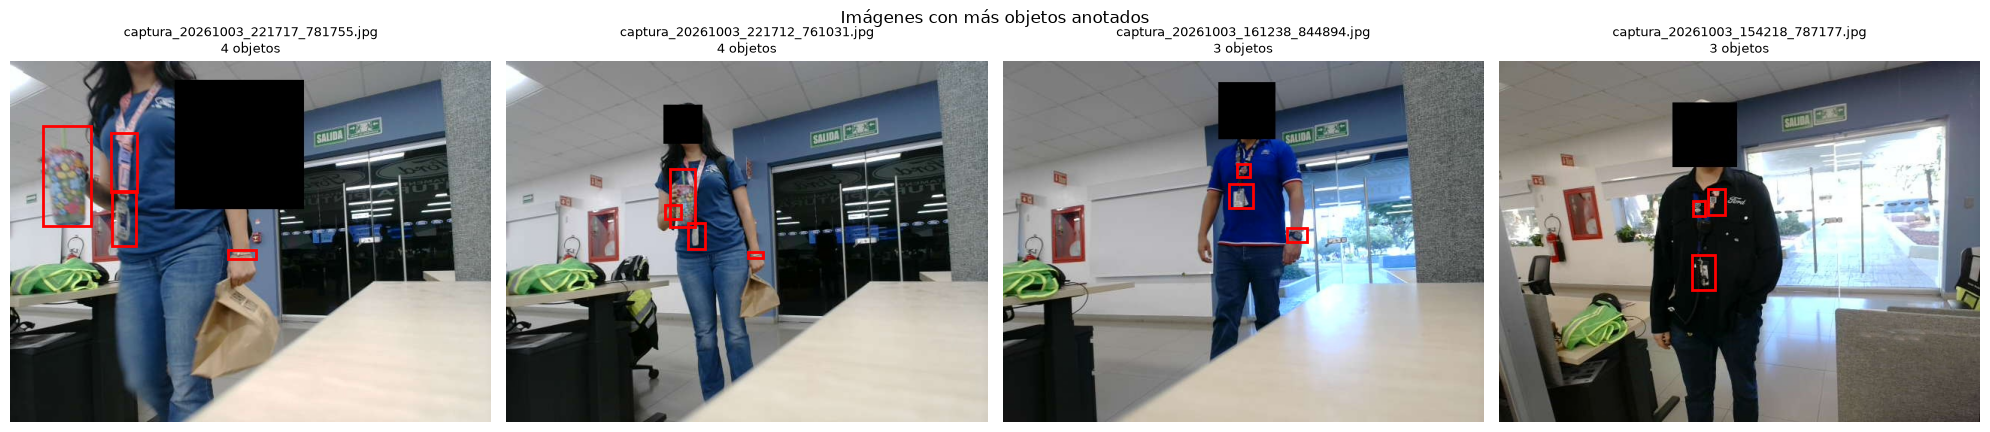

In [19]:
top_imgs = df_img.sort_values("n_objetos", ascending=False)["imagen"].head(4)
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, nombre in zip(axes, top_imgs):
    ax.imshow(Image.open(RAW_DIR / nombre).convert("RGB"))
    for _, r in df_obj[df_obj["imagen"] == nombre].iterrows():
        ax.add_patch(plt.Rectangle((r["x"], r["y"]), r["w"], r["h"], fill=False, lw=2, edgecolor="red"))
    ax.set_title(f"{nombre}\n{(df_obj['imagen'] == nombre).sum()} objetos", fontsize=9)
    ax.axis("off")
plt.suptitle("Imágenes con más objetos anotados")
plt.tight_layout()
plt.show()

## Tamaño vs. forma de las cajas
Se usa la correlación de **Spearman** (basada en rangos) porque las variables están sesgadas y tienen atípicos, casos en los que Pearson es poco confiable.

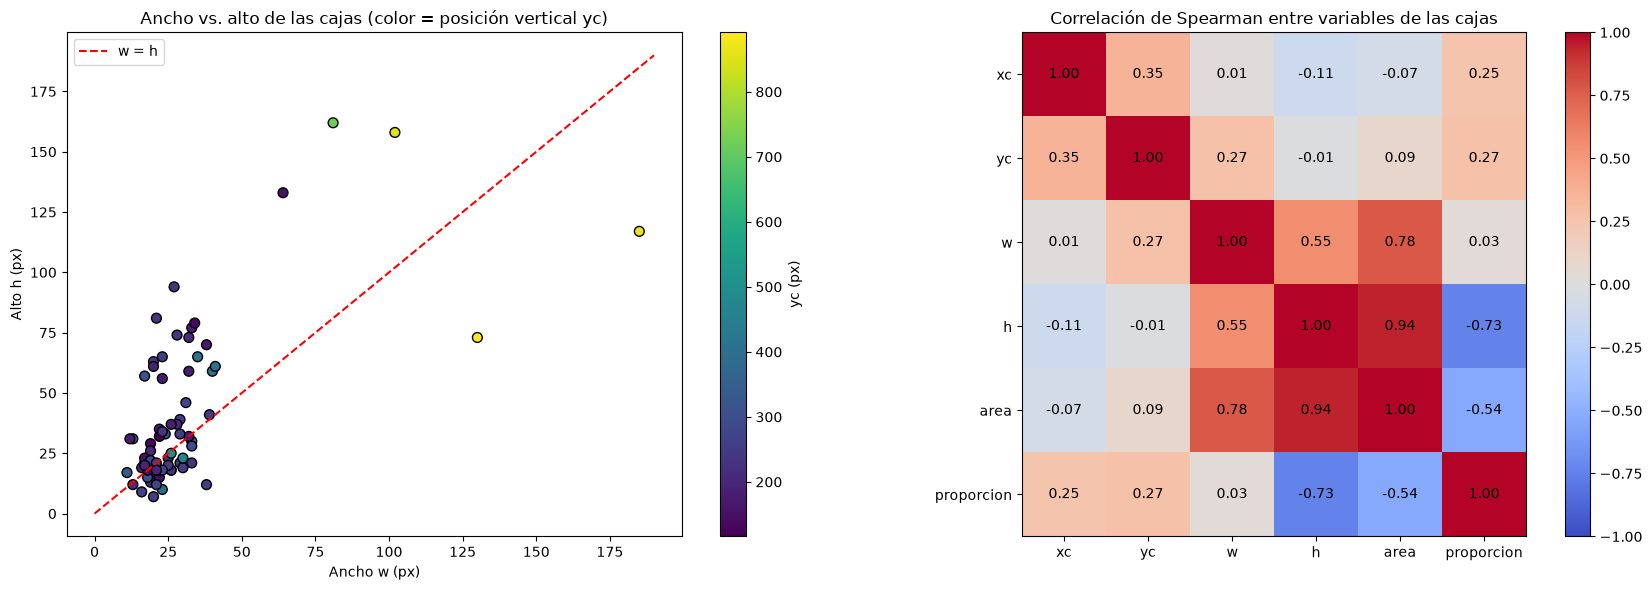

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sc = axes[0].scatter(df_obj["w"], df_obj["h"], c=df_obj["yc"], cmap="viridis", s=50, edgecolor="black")
lim = max(df_obj["w"].max(), df_obj["h"].max()) + 5
axes[0].plot([0, lim], [0, lim], "r--", label="w = h")
axes[0].set_xlabel("Ancho w (px)")
axes[0].set_ylabel("Alto h (px)")
axes[0].set_title("Ancho vs. alto de las cajas (color = posición vertical yc)")
axes[0].legend()
plt.colorbar(sc, ax=axes[0], label="yc (px)")

vars_corr = ["xc", "yc", "w", "h", "area", "proporcion"]
corr = df_obj[vars_corr].corr(method="spearman")
im = axes[1].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(vars_corr)), vars_corr)
axes[1].set_yticks(range(len(vars_corr)), vars_corr)
for i in range(len(vars_corr)):
    for j in range(len(vars_corr)):
        axes[1].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
axes[1].set_title("Correlación de Spearman entre variables de las cajas")
plt.colorbar(im, ax=axes[1])
plt.tight_layout()
plt.show()

**Interpretación.**
* Casi todos los puntos están por encima de la línea `w = h`, así que predominan los objetos verticales: lanyards, gafetes y plumas colgando.
* `area` está muy correlacionada con `h` (ρ = 0.92) y con `w` (ρ = 0.65). Como se calcula a partir de ellas, es una variable **redundante**.
* `proporcion` tiene una fuerte correlación negativa con `h` (ρ = −0.80): cuanto más alto es el objeto, más alargado es.
* La posición (`xc`, `yc`) casi no se relaciona con el tamaño (|ρ| ≤ 0.21), así que los objetos grandes y pequeños aparecen en las mismas zonas.

## Posición de los objetos dentro de la imagen

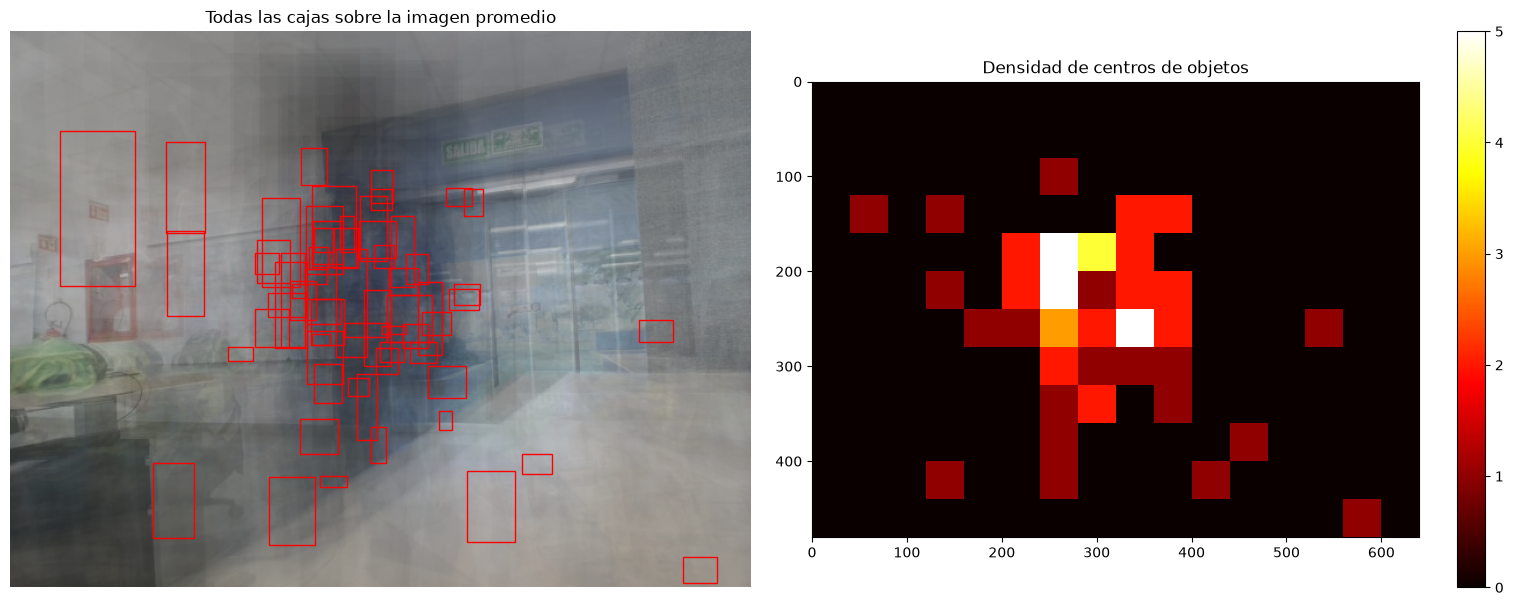

Región que contiene TODOS los objetos: x ∈ [43, 1378], y ∈ [86, 929]
Esa región ocupa el 366% de la imagen


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(mean_image.astype(np.uint8))
for _, r in df_obj.iterrows():
    axes[0].add_patch(plt.Rectangle((r["x"], r["y"]), r["w"], r["h"], fill=False, lw=1, edgecolor="red"))
axes[0].set_title("Todas las cajas sobre la imagen promedio")
axes[0].axis("off")

h2 = axes[1].hist2d(df_obj["xc"], df_obj["yc"], bins=[16, 12],
                    range=[[0, ANCHO_IMG], [0, ALTO_IMG]], cmap="hot")
axes[1].invert_yaxis()
axes[1].set_aspect("equal")
axes[1].set_title("Densidad de centros de objetos")
plt.colorbar(h2[3], ax=axes[1])
plt.tight_layout()
plt.show()

x_min, x_max = int(df_obj["x"].min()), int((df_obj["x"] + df_obj["w"]).max())
y_min, y_max = int(df_obj["y"].min()), int((df_obj["y"] + df_obj["h"]).max())
print(f"Región que contiene TODOS los objetos: x ∈ [{x_min}, {x_max}], y ∈ [{y_min}, {y_max}]")
print(f"Esa región ocupa el {(x_max - x_min) * (y_max - y_min) / (ANCHO_IMG * ALTO_IMG):.0%} de la imagen")

**Interpretación.**
* Los objetos se concentran en una **franja central** de la imagen (centros entre x ≈ 240–400 y y ≈ 150–350), que corresponde al pecho y la cintura del trabajador, donde se cuelgan gafetes, plumas y llaves.
* Todos los objetos caben en una región que ocupa el **49 %** de la imagen. El resto (techo, paredes y muebles) es fondo que no aporta información.
* Esta concentración justifica recortar una **región de interés (ROI)** para reducir la dimensionalidad (ver *Procesamiento*).

## Calidad de imagen vs. categoría (cumple / no cumple)

Correlación de Spearman con el número de objetos por imagen:
tamano_kb    0.10
brillo      -0.14
contraste    0.22
nitidez      0.22


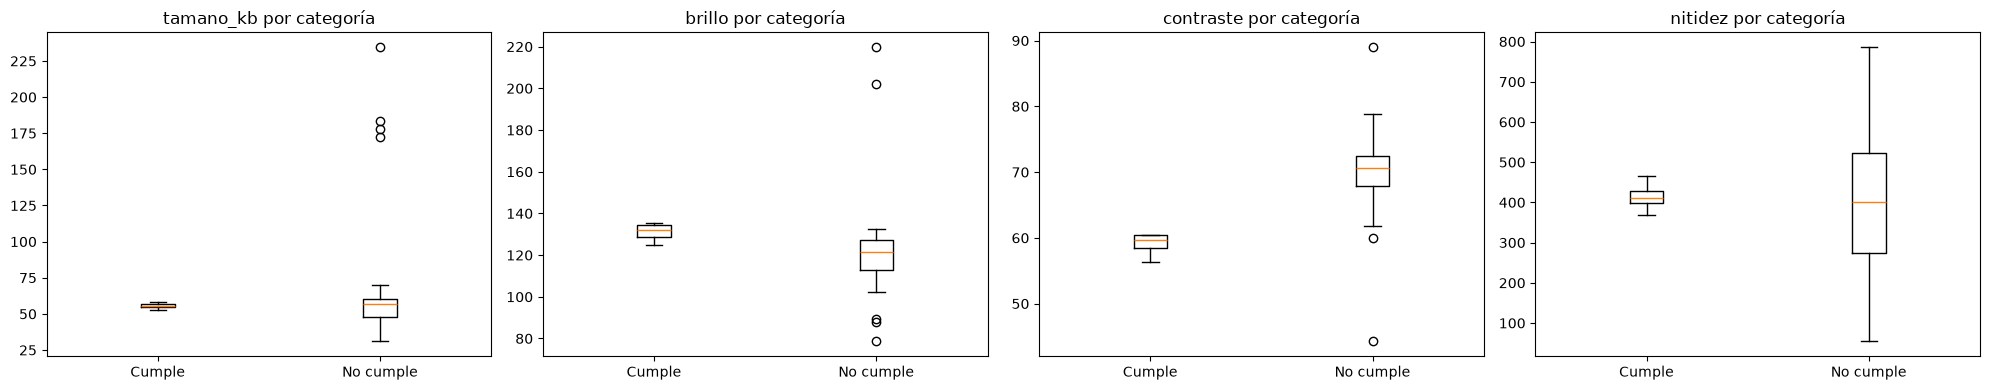

In [22]:
vars_img = ["tamano_kb", "brillo", "contraste", "nitidez", "n_objetos"]
corr_img = df_img[vars_img].corr(method="spearman")["n_objetos"].drop("n_objetos")
print("Correlación de Spearman con el número de objetos por imagen:")
print(corr_img.round(2).to_string())

grupos = ["Cumple (sin objetos)", "No cumple (con objetos)"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, ["tamano_kb", "brillo", "contraste", "nitidez"]):
    ax.boxplot([df_img.loc[df_img["cumple"] == g, col] for g in grupos])
    ax.set_xticks([1, 2], ["Cumple", "No cumple"])
    ax.set_title(f"{col} por categoría")
plt.tight_layout()
plt.show()

**Interpretación.**
* Las correlaciones entre la calidad de imagen y el número de objetos son débiles (|ρ| ≤ 0.29): la calidad de la captura no determina cuántos objetos se anotan.
* Las 5 imágenes de personal que *cumple* tienen valores casi idénticos entre sí y **menos contraste** (≈60 frente a ≈70). Esto no se debe a que cumplan, sino a que se tomaron en la misma ráfaga.
* **Riesgo:** un modelo podría aprender un atajo ("poco contraste = cumple") en lugar de aprender a ver los objetos. Por eso hay que capturar ejemplos negativos en distintas sesiones, con distintas personas y con distinta iluminación.

## Tendencias temporales
El nombre de cada archivo contiene la fecha y hora de captura (`captura_AAAAMMDD_HHMMSS_...`). Se agrupan en **sesiones** cuando hay más de 30 minutos entre capturas consecutivas.

,inicio,fin,imagenes,objetos,brillo_medio,nitidez_media
sesion,,,,,,
1,2026-10-03 15:30:16,2026-10-03 16:21:21,31,39,121.599998,394.299988
2,2026-10-03 19:24:37,2026-10-03 19:25:22,3,7,126.500000,607.799988
3,2026-10-03 21:11:50,2026-10-03 21:12:05,2,3,129.000000,271.100006
4,2026-10-03 22:04:04,2026-10-03 22:17:17,5,13,121.000000,558.500000
5,2026-10-10 17:40:08,2026-10-10 17:40:08,1,1,115.699997,54.700001
6,2026-10-19 10:51:51,2026-10-19 10:52:01,2,2,108.300003,80.599998
7,2026-10-22 13:09:34,2026-10-22 13:09:34,1,2,202.100006,136.500000


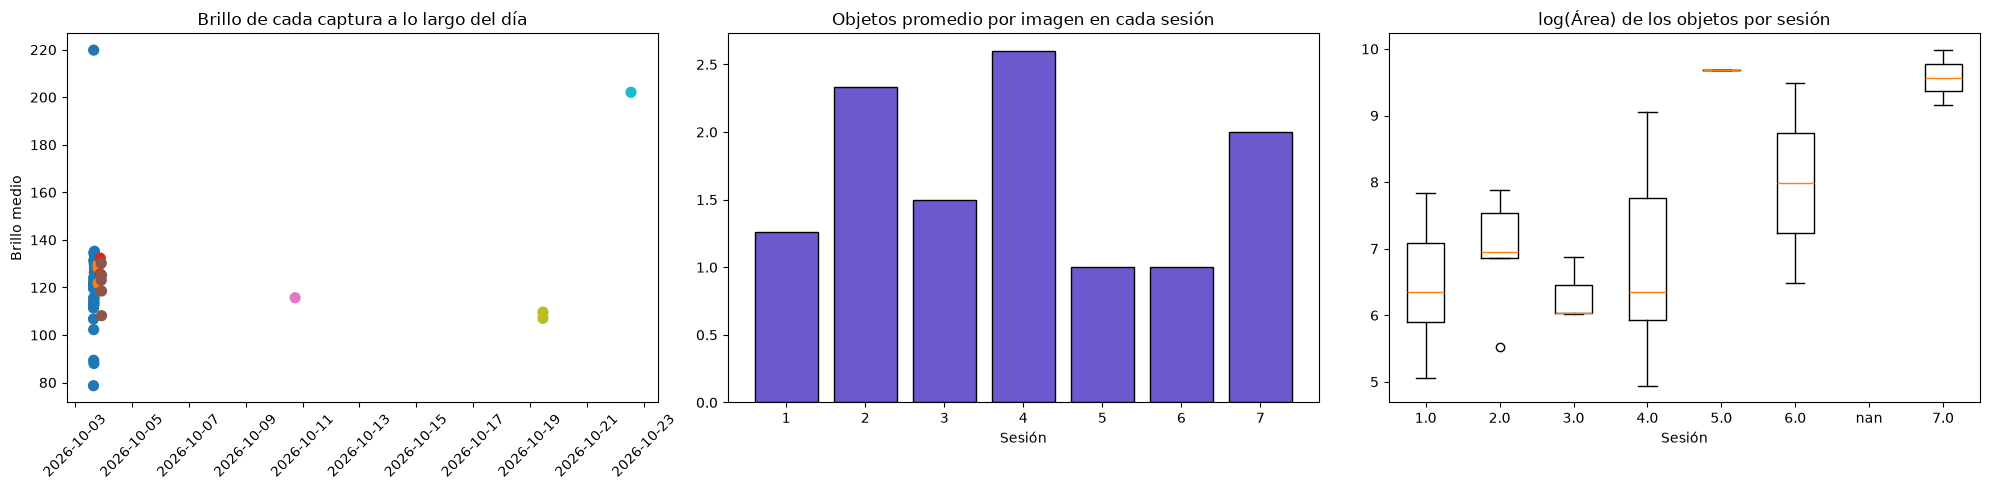

In [23]:
df_img["hora"] = pd.to_datetime(df_img["imagen"].str.extract(r"captura_(\d{8}_\d{6})")[0],
                                format="%Y%m%d_%H%M%S")
df_img = df_img.sort_values("hora").reset_index(drop=True)
df_img["sesion"] = (df_img["hora"].diff() > pd.Timedelta(minutes=30)).cumsum() + 1

por_sesion = df_img.groupby("sesion").agg(
    inicio=("hora", "min"), fin=("hora", "max"), imagenes=("imagen", "count"),
    objetos=("n_objetos", "sum"), brillo_medio=("brillo", "mean"), nitidez_media=("nitidez", "mean"),
)
display(por_sesion.round({"brillo_medio": 1, "nitidez_media": 1}))

df_obj = df_obj.merge(df_img[["imagen", "sesion"]], on="imagen", how="left")

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
axes[0].scatter(df_img["hora"], df_img["brillo"], c=df_img["sesion"], cmap="tab10", s=50)
axes[0].set_title("Brillo de cada captura a lo largo del día")
axes[0].set_ylabel("Brillo medio")
axes[0].tick_params(axis="x", rotation=45)
axes[1].bar(por_sesion.index.astype(str), por_sesion["objetos"] / por_sesion["imagenes"],
            color="slateblue", edgecolor="black")
axes[1].set_title("Objetos promedio por imagen en cada sesión")
axes[1].set_xlabel("Sesión")
sesiones = sorted(df_obj["sesion"].unique())
axes[2].boxplot([df_obj.loc[df_obj["sesion"] == s, "log_area"] for s in sesiones])
axes[2].set_xticks(range(1, len(sesiones) + 1), [str(s) for s in sesiones])
axes[2].set_title("log(Área) de los objetos por sesión")
axes[2].set_xlabel("Sesión")
plt.tight_layout()
plt.show()

**Interpretación.**
* Las capturas se hicieron en **4 sesiones del mismo día** (3 de octubre): de 15:30 a 16:21 (31 imágenes), a las 19:24 (3), a las 21:11 (2) y de 22:04 a 22:17 (5). El **76 %** de los datos proviene de la primera sesión.
* El brillo medio por sesión es estable (entre 121 y 129) porque la iluminación es artificial. La mayor variación ocurre dentro de la primera sesión, donde está la imagen sobreexpuesta.
* El número y el tamaño de los objetos varían entre sesiones, pero las sesiones 2 a 4 tienen tan pocas imágenes que no se puede afirmar una tendencia.
* **Implicación:** al dividir en entrenamiento y prueba conviene **separar por sesión** y no al azar. Las imágenes consecutivas de una ráfaga son casi idénticas, y mezclarlas haría que la evaluación saliera artificialmente alta.

# Procesamiento
Por el momento el procesamiento al que se han sometido las muestras han sido para protección de datos de identificación personal.  
Etapas posteriores buscarán mantener estandarizado el espacio de prueba, el fondo y si es posible la iluminación.  
Si hay complicaciones futuras se buscaría tambien eliminar esas imágenes que tengan recuadros negros de "falso positivo"

## 1. Limpieza de la tabla de anotaciones
**Justificación:** el análisis de valores faltantes mostró que las filas vacías no son datos perdidos sino registros redundantes o imágenes sin objetos. Por ello no se imputan: se eliminan las filas vacías redundantes y los duplicados, y las imágenes sin objetos se conservan como **ejemplos negativos** (personal que cumple).

Además se agregan coordenadas normalizadas entre 0 y 1 (formato YOLO: centro y tamaño de la caja), porque no dependen de la resolución y son el formato que usan los detectores de objetos.

In [24]:
df_limpio = df_obj[["imagen", "x", "y", "w", "h"]].copy()
df_limpio["clase"] = 0  # 0 = objeto con potencial de dañar la pintura
df_limpio["x_centro"] = (df_limpio["x"] + df_limpio["w"] / 2) / ANCHO_IMG
df_limpio["y_centro"] = (df_limpio["y"] + df_limpio["h"] / 2) / ALTO_IMG
df_limpio["ancho_norm"] = df_limpio["w"] / ANCHO_IMG
df_limpio["alto_norm"] = df_limpio["h"] / ALTO_IMG

negativas = pd.DataFrame({"imagen": imagenes_sin_objetos})
print(f"Filas originales: {len(df)}")
print(f"  -> objetos válidos: {len(df_limpio)}")
print(f"  -> imágenes negativas (sin objetos): {len(negativas)}")
print(f"  -> filas eliminadas: {len(df) - len(df_limpio) - len(negativas)}")
display(df_limpio.head())

df_limpio_export = pd.concat([df_limpio, negativas], ignore_index=True)
df_limpio_export.to_csv("../DataCapture/anotaciones_limpias.csv", index=False)
print("Se guardó ../DataCapture/anotaciones_limpias.csv")

Filas originales: 74
  -> objetos válidos: 68
  -> imágenes negativas (sin objetos): 6
  -> filas eliminadas: 0


,imagen,x,y,w,h,clase,x_centro,y_centro,ancho_norm,alto_norm
0,captura_20261003_153016_534962.jpg,223,384,40,59,0,0.379688,0.861458,0.062500,0.122917
1,captura_20261003_153021_540685.jpg,394,379,41,61,0,0.647656,0.853125,0.064062,0.127083
2,captura_20261003_153051_624221.jpg,254,205,19,13,0,0.411719,0.440625,0.029687,0.027083
3,captura_20261003_153056_648946.jpg,291,299,18,15,0,0.468750,0.638542,0.028125,0.031250
4,captura_20261003_153101_657504.jpg,243,218,13,12,0,0.389844,0.466667,0.020313,0.025000


Se guardó ../DataCapture/anotaciones_limpias.csv


## 2. Tratamiento de valores atípicos y distribuciones sesgadas
**Justificación:** las cajas atípicas se revisaron visualmente y corresponden a objetos reales (por ejemplo, lanyards o gafetes que son más largos que el resto), no a errores de anotación. Con solo 68 objetos, eliminarlos significaría perder justamente los ejemplos más variados, por lo que **se conservan**. Para el análisis estadístico se usa la transformación logarítmica, que reduce el sesgo y el número de atípicos.

La imagen sobreexpuesta detectada con los histogramas tampoco se elimina: contiene objetos anotados y se corrige con normalización (siguiente paso).

In [25]:
sesgos = pd.DataFrame({
    "sesgo original": [df_obj["area"].skew(), df_obj["proporcion"].skew()],
    "sesgo tras log": [df_obj["log_area"].skew(), df_obj["log_proporcion"].skew()],
}, index=["área", "proporción w/h"])
display(sesgos.round(2))
print(f"Atípicos en área: {atipicos_iqr(df_obj['area']).sum()} -> en log(área): {atipicos_iqr(df_obj['log_area']).sum()}")
print(f"Atípicos en proporción: {atipicos_iqr(df_obj['proporcion']).sum()} -> en log(proporción): {atipicos_iqr(df_obj['log_proporcion']).sum()}")

imagen_sobreexpuesta = df_diferencias_histograma.iloc[0]["imagen"]
n_obj_sobre = (df_obj["imagen"] == imagen_sobreexpuesta).sum()
print(f"\nImagen sobreexpuesta: {imagen_sobreexpuesta} (contiene {n_obj_sobre} objetos anotados)")

,sesgo original,sesgo tras log
área,3.87,0.96
proporción w/h,1.56,0.01


Atípicos en área: 5 -> en log(área): 3
Atípicos en proporción: 3 -> en log(proporción): 0

Imagen sobreexpuesta: captura_20261022_130934_236528.jpg (contiene 2 objetos anotados)


## 3. Normalización de las imágenes
**¿Se deberían normalizar las imágenes para visualizarlas mejor?** Se compara la imagen sobreexpuesta original contra dos técnicas:
* **Min-max:** estira el rango de intensidades a 0-255.
* **CLAHE** (ecualización adaptativa del histograma): ajusta el contraste por regiones sobre el canal de luminosidad, sin alterar los colores.

Rango de intensidades de la imagen original: 0 - 255


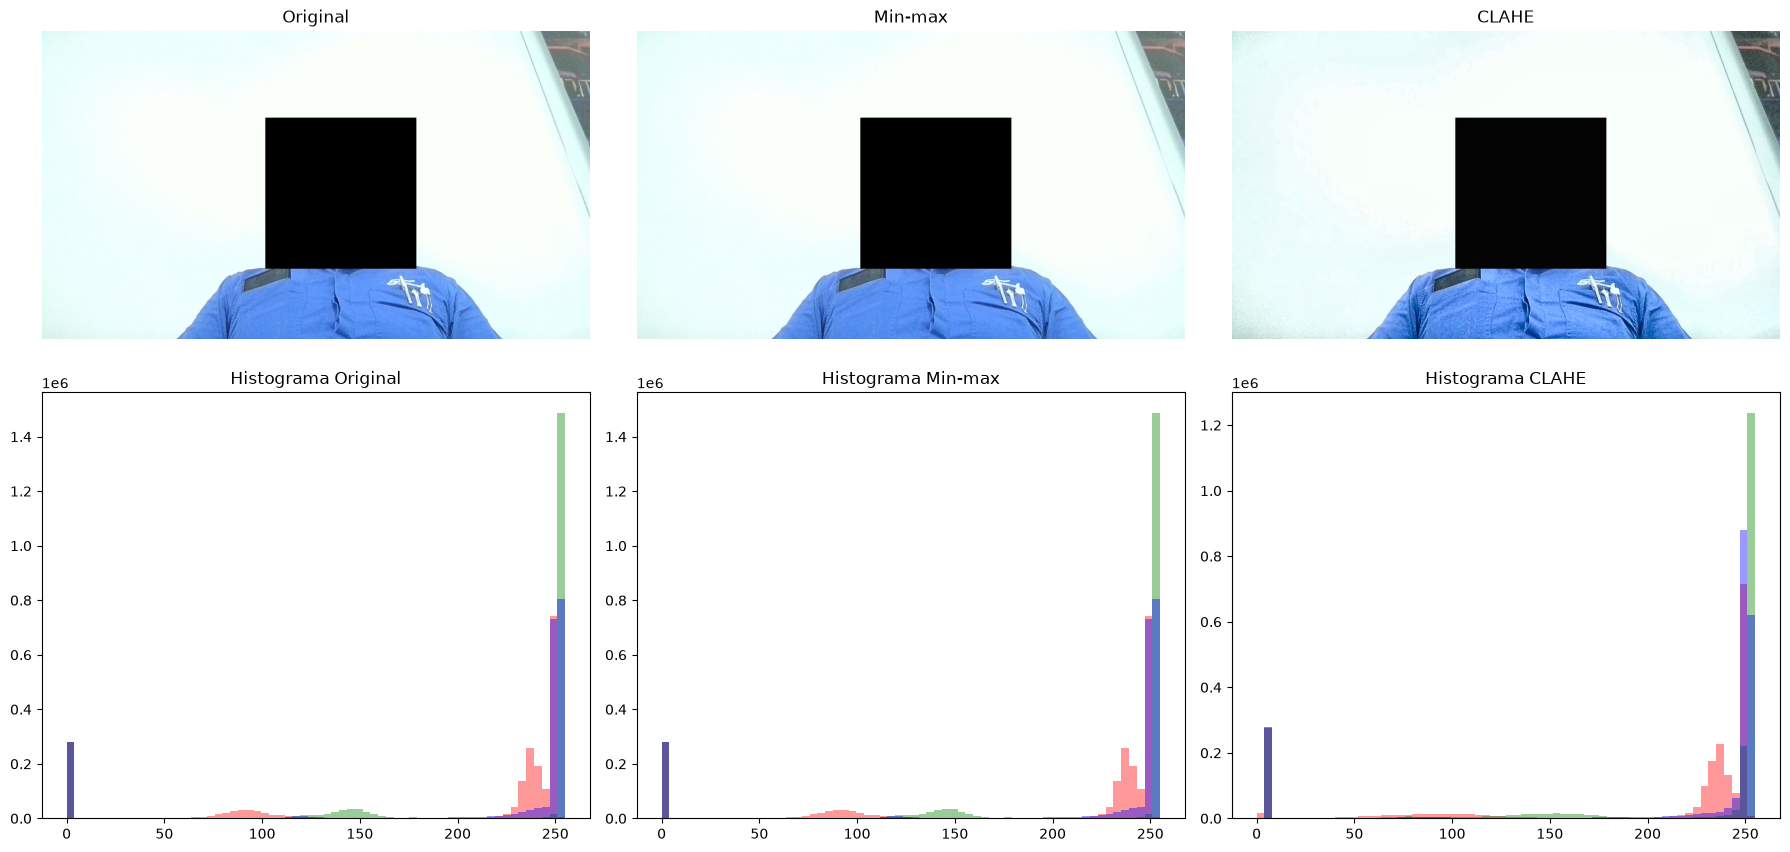

In [26]:
def aplicar_clahe(img_rgb):
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    lab[:, :, 0] = clahe.apply(lab[:, :, 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)


def minmax(img_rgb):
    img = img_rgb.astype(np.float32)
    return ((img - img.min()) / (img.max() - img.min() + 1e-6) * 255).astype(np.uint8)


original = np.asarray(Image.open(RAW_DIR / imagen_sobreexpuesta).convert("RGB"))
print(f"Rango de intensidades de la imagen original: {original.min()} - {original.max()}")
versiones = {"Original": original, "Min-max": minmax(original), "CLAHE": aplicar_clahe(original)}

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for k, (titulo, img) in enumerate(versiones.items()):
    axes[0, k].imshow(img)
    axes[0, k].set_title(titulo)
    axes[0, k].axis("off")
    for c, color in enumerate(["red", "green", "blue"]):
        axes[1, k].hist(img[:, :, c].ravel(), bins=64, range=(0, 255), color=color, alpha=0.4)
    axes[1, k].set_title(f"Histograma {titulo}")
plt.tight_layout()
plt.show()

In [27]:
## Efecto de CLAHE sobre todo el conjunto
filas = []
for path in image_paths:
    img = np.asarray(Image.open(path).convert("RGB"))
    for etiqueta, version in [("original", img), ("CLAHE", aplicar_clahe(img))]:
        gris = cv2.cvtColor(version, cv2.COLOR_RGB2GRAY).astype(np.float32)
        filas.append({"version": etiqueta, "brillo": gris.mean(), "contraste": gris.std()})
efecto = pd.DataFrame(filas).groupby("version")[["brillo", "contraste"]].agg(["mean", "std"])
display(efecto.round(1))

brillo             contraste     
                mean        std       mean  std
version                                        
CLAHE     126.900002  20.000000  66.199997  6.2
original  123.300003  22.799999  68.099998  7.2

**Interpretación.**
* **Min-max no tiene efecto:** la imagen ya ocupa todo el rango 0–255, porque el recuadro negro de la cara fija el mínimo en 0 y las zonas quemadas fijan el máximo en 255.
* **CLAHE sí mejora la visualización:** recupera detalle en los tonos medios (camisa, pantalón y objetos en la bolsa) sin alterar los colores. Lo que no puede recuperar son las zonas saturadas en 255, porque esa información se perdió al capturar.
* En todo el conjunto, CLAHE reduce la variación entre imágenes: la desviación estándar del brillo baja de 20.1 a 17.1 y la del contraste de 6.5 a 5.2. Las imágenes quedan más homogéneas.
* **Respuesta:** sí conviene normalizar con CLAHE, tanto para visualizar como para preprocesar. Para el modelo, además, los píxeles se escalarán a [0, 1]. La imagen sobreexpuesta se conserva ya corregida, pero se recomienda ajustar la exposición de la cámara para que no se repita.

## 4. Selección de características y reducción de dimensionalidad
En imágenes las características son los píxeles: una imagen de 640×480 a color tiene **921,600** valores. Se evalúan cuatro estrategias para reducir la dimensionalidad sin perder información útil:
1. **Región de interés (ROI):** recortar la zona donde aparecen los objetos.
2. **Escala de grises:** útil si los canales de color son redundantes.
3. **Reducir resolución:** verificar cuánto se encogen los objetos.
4. **PCA sobre los recortes:** cuántas componentes explican la apariencia de los objetos.

In [28]:
## (1) Región de interés
n_original = ANCHO_IMG * ALTO_IMG * 3
margen = 20
roi = (max(0, x_min - margen), max(0, y_min - margen),
       min(ANCHO_IMG, x_max + margen), min(ALTO_IMG, y_max + margen))
n_roi = (roi[2] - roi[0]) * (roi[3] - roi[1]) * 3
print(f"Características por imagen completa: {n_original:,}")
print(f"ROI con margen de {margen}px: x ∈ [{roi[0]}, {roi[2]}], y ∈ [{roi[1]}, {roi[3]}] "
      f"-> {n_roi:,} características ({1 - n_roi / n_original:.0%} menos)")

## (2) Redundancia entre canales de color (muestra de píxeles de todas las imágenes)
pixeles = np.concatenate([img.reshape(-1, 3)[::50] for img in images_rgb])
corr_rgb = pd.DataFrame(np.corrcoef(pixeles.T), index=channel_names, columns=channel_names)
print("\nCorrelación entre canales RGB:")
display(corr_rgb.round(3))

## (3) Tamaño de los objetos al reducir la resolución
filas = []
for lado in [640, 416, 320, 224]:
    escala = lado / ANCHO_IMG
    lado_menor = np.minimum(df_obj["w"], df_obj["h"]) * escala
    filas.append({"ancho de entrada (px)": lado,
                  "lado menor mediano del objeto (px)": lado_menor.median(),
                  "objetos con lado menor < 8 px": int((lado_menor < 8).sum())})
display(pd.DataFrame(filas).round(1))

Características por imagen completa: 921,600
ROI con margen de 20px: x ∈ [23, 640], y ∈ [66, 480] -> 766,314 características (17% menos)

Correlación entre canales RGB:


,Rojo,Verde,Azul
Rojo,1.000,0.980,0.921
Verde,0.980,1.000,0.969
Azul,0.921,0.969,1.000


,ancho de entrada (px),lado menor mediano del objeto (px),objetos con lado menor < 8 px
0,640,21.0,1
1,416,13.6,8
2,320,10.5,12
3,224,7.4,37


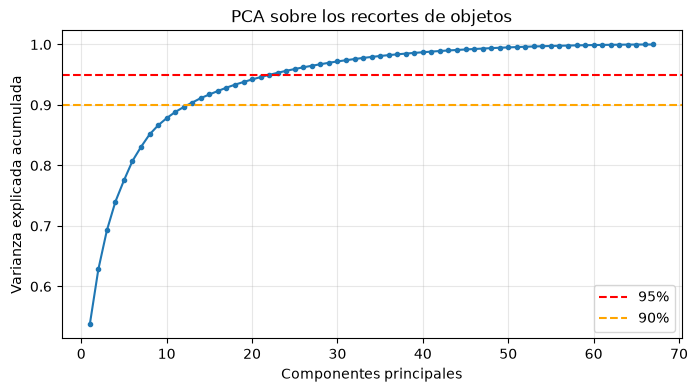

Componentes para 90% de varianza: 13 | para 95%: 23 (de 576 características)


In [29]:
## (4) PCA sobre los recortes de objetos (24x24 en escala de grises = 576 características)
X = np.stack([
    np.asarray(Image.open(p).convert("L").resize((24, 24)), dtype=np.float32).ravel() / 255
    for p in sorted(object_files)
])
Xc = X - X.mean(axis=0)
_, s, _ = np.linalg.svd(Xc, full_matrices=False)
var_exp = np.cumsum(s ** 2) / np.sum(s ** 2)
k90 = int(np.argmax(var_exp >= 0.90)) + 1
k95 = int(np.argmax(var_exp >= 0.95)) + 1

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(var_exp) + 1), var_exp, marker="o", ms=3)
plt.axhline(0.95, color="red", ls="--", label="95%")
plt.axhline(0.90, color="orange", ls="--", label="90%")
plt.xlabel("Componentes principales")
plt.ylabel("Varianza explicada acumulada")
plt.title("PCA sobre los recortes de objetos")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print(f"Componentes para 90% de varianza: {k90} | para 95%: {k95} (de {X.shape[1]} características)")

**Interpretación y decisiones.**
1. **ROI:** todos los objetos están dentro de la región x ∈ [126, 569], y ∈ [105, 446], la zona del torso. Recortarla con un margen de 20 px elimina el **40 %** de las características sin perder ningún objeto. Como la posición de la cámara puede cambiar en la línea, el recorte debe validarse con capturas del puesto final.
2. **Escala de grises:** los canales RGB están muy correlacionados (ρ entre 0.92 y 0.98), y pasar a gris reduciría las características a un tercio. Sin embargo, varios objetos se distinguen por su color (lanyards azules, objetos rojos o naranjas), así que **se conserva el color**. La escala de grises queda como alternativa para modelos ligeros.
3. **Resolución:** reducir la imagen es la forma más común de bajar la dimensionalidad, pero aquí es riesgoso. A 320 px de ancho, 18 de los 68 objetos quedarían con un lado menor a 8 px, y a 224 px serían 49. **Se recomienda mantener 640 px** (o como mínimo 416 px) y reducir la dimensionalidad con la ROI.
4. **PCA:** la apariencia de los objetos (576 píxeles por recorte) se explica con 11 componentes al 90 % y con 20 al 95 %. Hay mucha redundancia, lo que sería útil si más adelante se entrena un clasificador ligero sobre los recortes. Con solo 68 muestras, este resultado es preliminar.

# Conclusiones
Un proyecto de visión artificial enfocado a inspeccionar al personal requiere algunos enfoques peculiares:
## PII
Grabar a gente en general requiere de tomar consideraciones y protecciones adicionales ya que existe el riesgo de incurrir en problemas de ciberseguridad al exponer las llamadas PII (personal identificación information).  
Para efectos del proyecto se hizo un preprocesamiento que garantice que los rostros no sean visibles para un desarrollador externo.  Para la ejecución se debe hacer de manera local y sin enviar datos a través de internet, mientras que los controles establecidos para desarrollo del entrenamiento obligan a ocultar los rostros de las personas a pesar de tener su consentimiento.

## Ejecución
La ejecución debe ser offline y anonima.  El sistema de cubrimiento de rostros sigue vigente en la ejecución y solo se encargará de almacenar datos de detección ya que la principal función es *alertar al personal sobre lo que debe de corregir en su uniforme*. 

## Datos como imágenes

El proyecto de inspección visual requiere un enfoque donde los datos generados pueden actualizarse del mismo entorno de pruebas o producción.  Así mismo al no ser inherentemente un dato numéricos, sino un espacio 2D o una matriz donde es más importante una serie de relaciones espaciales que el de un valor, obtener datos descriptivos puede resultar abstracto.  *Un detector de imágenes anomalas* podría ser clave para una prediscriminación de imágenes que hayan sido capturadas bajo condiciones muy inusuales.  Tal enfoque permitiría conseguir datos de utilidad para una IA.